# ทำนายชั่วโมงการนอนคืนถัดไป (Mixed Sleep: LifeSnaps + GLOBEM)

Target: `sleep_hours_next` (regression) — ดูขอบเขตงานใน `README.md`

| ส่วน | เนื้อหา |
|---|---|
| 1 | เตรียมข้อมูล + คัดกรอง 3 กฎ |
| 2 | Features + ทดสอบ leakage + features_example.csv |
| 3 | โมเดล (M0–M3) + 5-fold grouped CV |
| 4 | ประเมินผลบน test, feature importance, error analysis |
| 5 | ไฟล์ส่งงาน: results.csv, sleep_plot.png |
| 6 | โบนัส: Personalisation |

## 1. เตรียมข้อมูล

### 1.0 Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# brief อ้าง data/processed/ แต่รองรับกรณีไฟล์อยู่ที่โฟลเดอร์หลักด้วย
CANDIDATES = [Path("data/processed/mixed_sleep_tasks.csv"), Path("mixed_sleep_tasks.csv")]
DATA_PATH = next(p for p in CANDIDATES if p.exists())

TARGET = "sleep_hours_next"
SOURCES = ["globem", "lifesnaps"]
SPLITS = ["train", "test"]

pd.set_option("display.max_columns", 50)
print("data:", DATA_PATH)

data: mixed_sleep_tasks.csv


### 1.1 โหลดข้อมูล และเรียงตาม participant_id → date

การเรียงลำดับนี้จำเป็นสำหรับ lag / rolling ในส่วนที่ 2

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
raw = raw.sort_values(["participant_id", "date"]).reset_index(drop=True)

print("shape:", raw.shape)
print("participants:", raw["participant_id"].nunique())
print("date range:", raw["date"].min().date(), "→", raw["date"].max().date())
raw.head()

shape: (41733, 21)
participants: 733
date range: 2018-04-03 → 2022-01-21


,participant_id,source,cohort,date,split,cv_fold,sleep_hours_next,sleep_efficiency_next,steps,lastnight_minutesAsleep,lastnight_time_in_bed_min,lastnight_minutesAwake,lastnight_minutesToFallAsleep,lastnight_minutesAfterWakeup,lastnight_sleep_efficiency,mean7d_steps,mean7d_minutesAsleep,mean7d_sleep_efficiency,day_of_week,is_weekend,is_globem
0,621e2e8e67b776a24055b564,lifesnaps,LifeSnaps,2021-05-24,train,1,7.6667,94.0,8833.0,445.0,521.0,76.0,0.0,0.0,93.0,NaN,NaN,NaN,0,0,0
1,621e2e8e67b776a24055b564,lifesnaps,LifeSnaps,2021-05-25,train,1,8.2167,96.0,9727.0,460.0,548.0,88.0,0.0,0.0,94.0,NaN,NaN,NaN,1,0,0
2,621e2e8e67b776a24055b564,lifesnaps,LifeSnaps,2021-05-26,train,1,9.0000,93.0,8253.0,493.0,560.0,67.0,0.0,0.0,96.0,8937.7,466.0,94.333,2,0,0
3,621e2e8e67b776a24055b564,lifesnaps,LifeSnaps,2021-05-27,train,1,8.2167,94.0,9015.0,540.0,627.0,87.0,0.0,0.0,93.0,8957.0,484.5,94.000,3,0,0
4,621e2e8e67b776a24055b564,lifesnaps,LifeSnaps,2021-05-28,train,1,7.8500,95.0,12949.0,493.0,561.0,68.0,0.0,0.0,94.0,9755.4,486.2,94.000,4,0,0


### 1.1b ตรวจไฟล์ CSV ประกอบ — ทำไมใช้ `mixed_sleep_tasks.csv` ไฟล์เดียว

ในโฟลเดอร์มีไฟล์ LifeSnaps แบบคอลัมน์เต็ม (`lifesnaps_tasks.csv`, 74 คอลัมน์) และผลอ้างอิง (`pooling_results.csv`)
cell นี้ตรวจว่า (1) ข้อมูล LifeSnaps ในไฟล์หลักตรงกับไฟล์เต็ม (2) คอลัมน์ที่เพิ่มมาใช้ได้หรือไม่
— ข้ามได้ถ้าไม่มีไฟล์ (notebook ยังรันได้)

In [3]:
EXTRA = {name: DATA_PATH.parent / name for name in
         ["lifesnaps_tasks.csv", "lifesnaps_splits.csv", "pooling_results.csv"]}

if all(p.exists() for p in EXTRA.values()):
    ls_full = pd.read_csv(EXTRA["lifesnaps_tasks.csv"], parse_dates=["date"])
    ls_splits = pd.read_csv(EXTRA["lifesnaps_splits.csv"])
    ls_main = raw[raw["source"] == "lifesnaps"]

    # (1) แถวที่ซ้ำกันต้องมีค่าเท่ากัน
    both = ls_main.merge(ls_full, on=["participant_id", "date"], how="outer",
                         suffixes=("_main", "_full"), indicator=True)
    print("แถว: ", both["_merge"].value_counts().to_dict())
    common = both[both["_merge"] == "both"]
    for c in ["sleep_hours_next", "steps", "lastnight_minutesAsleep", "mean7d_minutesAsleep", "split", "cv_fold"]:
        a, b = common[f"{c}_main"], common[f"{c}_full"]
        if pd.api.types.is_numeric_dtype(a):
            same = np.isclose(a, b, atol=0.01, equal_nan=True)
        else:
            same = (a == b) | (a.isna() & b.isna())
        print(f"  {c:<24} ตรงกัน {np.mean(same):.1%}")
    only_full = both[both["_merge"] == "right_only"]
    print(f"แถวที่มีเฉพาะในไฟล์เต็ม: {len(only_full)} (target ว่างทั้งหมด = {only_full['sleep_hours_next_full'].isna().all()}"
          " → กฎ R1 ตัดทิ้งอยู่แล้ว)")

    split_check = ls_main.groupby("participant_id")[["split", "cv_fold"]].first().join(
        ls_splits.set_index("participant_id"), rsuffix="_file", how="inner")
    print(f"split/cv_fold ตรงกับ lifesnaps_splits.csv: "
          f"{((split_check.split == split_check.split_file) & (split_check.cv_fold == split_check.cv_fold_file)).mean():.0%}"
          f" ({len(split_check)} คน)")

    # (2) คอลัมน์ที่มีเฉพาะ LifeSnaps
    extra_cols = sorted(set(ls_full.columns) - set(raw.columns))
    miss = ls_full[extra_cols].isna().mean().mul(100)
    print(f"\nคอลัมน์ที่มีเฉพาะใน lifesnaps_tasks.csv: {len(extra_cols)} — GLOBEM (~92% ของแถว) ไม่มีเลย")
    print("  เสี่ยงข้อมูลอนาคต:", [c for c in extra_cols if c.endswith("_next")])
    print(f"  ค่าว่าง ≥ 50%: {(miss >= 50).sum()} คอลัมน์ (เช่น spo2 {miss['spo2']:.0f}%, scl_avg {miss['scl_avg']:.0f}%)")

    # (3) pooling_results = ที่มาของค่าอ้างอิงใน brief
    pool = pd.read_csv(EXTRA["pooling_results.csv"])
    ref = pool[(pool["target"] == TARGET) & (pool["model"] == "hist-GBM") & pool["train on"].str.contains("other")]
    print("\nค่าอ้างอิง (hist-GBM เทรนรวม 2 แหล่ง):")
    display(ref[["evaluated on", "train on", "cv_MAE", "test_MAE"]])
else:
    print("ไม่พบไฟล์ประกอบ — ข้ามการตรวจ")

แถว:  {'both': 3441, 'right_only': 8, 'left_only': 0}
  sleep_hours_next         ตรงกัน 100.0%
  steps                    ตรงกัน 100.0%
  lastnight_minutesAsleep  ตรงกัน 100.0%
  mean7d_minutesAsleep     ตรงกัน 100.0%
  split                    ตรงกัน 100.0%
  cv_fold                  ตรงกัน 100.0%
แถวที่มีเฉพาะในไฟล์เต็ม: 8 (target ว่างทั้งหมด = True → กฎ R1 ตัดทิ้งอยู่แล้ว)
split/cv_fold ตรงกับ lifesnaps_splits.csv: 100% (65 คน)

คอลัมน์ที่มีเฉพาะใน lifesnaps_tasks.csv: 56 — GLOBEM (~92% ของแถว) ไม่มีเลย
  เสี่ยงข้อมูลอนาคต: ['stress_score_next']
  ค่าว่าง ≥ 50%: 23 คอลัมน์ (เช่น spo2 69%, scl_avg 96%)

ค่าอ้างอิง (hist-GBM เทรนรวม 2 แหล่ง):


,evaluated on,train on,cv_MAE,test_MAE
3,lifesnaps,lifesnaps + other,1.018,0.941
7,globem,globem + other,1.102,1.143


**สรุป:** ใช้ `mixed_sleep_tasks.csv` ไฟล์เดียว — ข้อมูล LifeSnaps ในไฟล์หลักตรงกับไฟล์เต็ม 100%
ส่วนคอลัมน์ที่เพิ่มมา GLOBEM ไม่มี (brief: รวม 2 แหล่ง "ด้วย features ที่มีร่วมกัน"), มีคอลัมน์ข้อมูลอนาคต และค่าว่างสูง
`pooling_results.csv` ใช้เทียบความสมเหตุสมผลของผลเท่านั้น

### 1.2 ตรวจความถูกต้องของ split / cv_fold (กันข้อมูลรั่ว)

In [4]:
per_pid = raw.groupby("participant_id").agg(
    n_split=("split", "nunique"),
    n_fold=("cv_fold", "nunique"),
    n_source=("source", "nunique"),
)
train_ids = set(raw.loc[raw["split"] == "train", "participant_id"])
test_ids = set(raw.loc[raw["split"] == "test", "participant_id"])

checks = {
    "ไม่มีแถวซ้ำ (participant_id, date)": not raw.duplicated(["participant_id", "date"]).any(),
    "แต่ละคนอยู่ split เดียว": (per_pid["n_split"] == 1).all(),
    "แต่ละคนอยู่ cv_fold เดียว": (per_pid["n_fold"] == 1).all(),
    "แต่ละคนมาจาก source เดียว": (per_pid["n_source"] == 1).all(),
    "ไม่มีคนซ้ำระหว่าง train/test": len(train_ids & test_ids) == 0,
    "test ทุกแถวมี cv_fold = -1": (raw.loc[raw["split"] == "test", "cv_fold"] == -1).all(),
    "train มี cv_fold 0–4 เท่านั้น": set(raw.loc[raw["split"] == "train", "cv_fold"]) == {0, 1, 2, 3, 4},
    "is_globem ตรงกับ source": (raw["is_globem"] == (raw["source"] == "globem").astype(int)).all(),
}
for name, ok in checks.items():
    print(("PASS" if ok else "FAIL"), "-", name)
assert all(checks.values())

print(f"\ntrain: {len(train_ids)} คน | test: {len(test_ids)} คน")
pd.crosstab(raw["cohort"], raw["split"], margins=True)

PASS - ไม่มีแถวซ้ำ (participant_id, date)
PASS - แต่ละคนอยู่ split เดียว
PASS - แต่ละคนอยู่ cv_fold เดียว
PASS - แต่ละคนมาจาก source เดียว
PASS - ไม่มีคนซ้ำระหว่าง train/test
PASS - test ทุกแถวมี cv_fold = -1
PASS - train มี cv_fold 0–4 เท่านั้น
PASS - is_globem ตรงกับ source

train: 587 คน | test: 146 คน


split,test,train,All
cohort,,,
INS-W_1,1572,5704,7276
INS-W_2,2107,8743,10850
INS-W_3,1782,6125,7907
INS-W_4,2267,9992,12259
LifeSnaps,656,2785,3441
All,8384,33349,41733


### 1.3 ยืนยันความสัมพันธ์ที่ทำให้เกิด leakage

brief ระบุว่า `sleep_hours_next[t] × 60 == lastnight_minutesAsleep[t+1]` — ตรวจซ้ำเพื่อยืนยันว่า
**ห้ามใช้ข้อมูลวัน t+1** (เช่น `shift(-1)`) ในการสร้าง feature

In [5]:
g = raw.groupby("participant_id")
next_day_gap = (g["date"].shift(-1) - raw["date"]).dt.days
next_asleep = g["lastnight_minutesAsleep"].shift(-1)

m = (next_day_gap == 1) & next_asleep.notna()
match = np.isclose(raw.loc[m, TARGET] * 60, next_asleep[m], atol=0.5)
print(f"วันติดกันที่ตรวจได้: {m.sum():,} คู่ | ตรงกัน: {match.mean():.2%}")

วันติดกันที่ตรวจได้: 37,673 คู่ | ตรงกัน: 100.00%


### 1.4 ภาพรวมค่าว่าง (ก่อนคัดกรอง) แยกตามแหล่ง

In [6]:
missing = (
    raw.drop(columns=["participant_id", "date"])
    .isna()
    .groupby(raw["source"])
    .mean()
    .mul(100)
    .round(1)
    .T
)
missing = missing[missing.sum(axis=1) > 0]
print("% ค่าว่าง (เฉพาะคอลัมน์ที่มีค่าว่าง)")
missing

% ค่าว่าง (เฉพาะคอลัมน์ที่มีค่าว่าง)


source,globem,lifesnaps
steps,2.6,0.5
lastnight_minutesAsleep,9.4,13.0
lastnight_time_in_bed_min,9.4,13.0
lastnight_minutesAwake,9.4,13.0
lastnight_minutesToFallAsleep,9.4,13.0
lastnight_minutesAfterWakeup,9.4,13.0
lastnight_sleep_efficiency,9.4,13.0
mean7d_steps,7.4,3.5
mean7d_minutesAsleep,9.2,9.4
mean7d_sleep_efficiency,9.3,9.4


In [7]:
# ช่องว่างระหว่างวัน (วันที่ไม่มีแถว) — ส่วนที่ 2 ต้องใช้วันที่จริงในการทำ lag ไม่ใช่ตำแหน่งแถว
gap_days = raw.groupby("participant_id")["date"].diff().dt.days
print(gap_days.value_counts().sort_index().head(8).rename("จำนวน").to_frame().T)
print(f"\nแถวที่ห่างจากแถวก่อนหน้า > 1 วัน: {(gap_days > 1).sum():,}")

date     1.0   2.0  3.0  4.0  5.0  6.0  7.0  8.0
จำนวน  37673  2233  453  214  109   65   53   36

แถวที่ห่างจากแถวก่อนหน้า > 1 วัน: 3,327


### 1.5 คัดกรอง 3 กฎ (ตามลำดับ)

| กฎ | เงื่อนไขที่ **ตัดออก** | เหตุผล |
|---|---|---|
| R1 | `sleep_hours_next` เป็น NaN | ไม่มี label — **ห้าม impute target** |
| R2 | `lastnight_minutesAsleep` **และ** `mean7d_minutesAsleep` เป็น NaN ทั้งคู่ | ไม่มีประวัติการนอนเลย |
| R3 | `steps` เป็น NaN หรือ = 0 | ไม่ได้สวมนาฬิการะหว่างวัน |

**หมายเหตุ:** เก็บ `raw` (ข้อมูลเต็มที่เรียงแล้ว) ไว้ใช้คำนวณ lag / rolling ในส่วนที่ 2 —
แถวที่ถูกตัดยังเป็น "ประวัติ" ที่รู้ได้ ณ วันที่ t (ถ้ามีค่า) เราตัดเฉพาะแถวที่ใช้ train / ประเมินเท่านั้น

In [8]:
RULES = {
    "R1: target ไม่ว่าง": raw[TARGET].notna(),
    "R2: มีประวัติการนอน": raw["lastnight_minutesAsleep"].notna() | raw["mean7d_minutesAsleep"].notna(),
    "R3: steps > 0": raw["steps"].notna() & (raw["steps"] > 0),
}

def count_rows(mask):
    sub = raw[mask]
    c = sub.groupby(["split", "source"]).size().reindex(
        pd.MultiIndex.from_product([SPLITS, SOURCES]), fill_value=0
    )
    c[("all", "all")] = len(sub)
    return c

keep = pd.Series(True, index=raw.index)
steps_log = {"0: ข้อมูลตั้งต้น": count_rows(keep)}
for name, rule_mask in RULES.items():
    keep &= rule_mask
    steps_log[name] = count_rows(keep)

filter_counts = pd.DataFrame(steps_log).T
filter_counts.columns = [f"{s}_{src}" if s != "all" else "total" for s, src in filter_counts.columns]
removed = (-filter_counts.diff()).fillna(0).astype(int)
removed.index = [f"ตัดออกโดย {i}" if k else "-" for k, i in enumerate(removed.index)]

print("จำนวนแถวที่เหลือหลังแต่ละกฎ (สะสม)")
display(filter_counts)
print("จำนวนแถวที่ถูกตัดในแต่ละกฎ")
display(removed.iloc[1:])

จำนวนแถวที่เหลือหลังแต่ละกฎ (สะสม)


,train_globem,train_lifesnaps,test_globem,test_lifesnaps,total
0: ข้อมูลตั้งต้น,30564,2785,7728,656,41733
R1: target ไม่ว่าง,30564,2785,7728,656,41733
R2: มีประวัติการนอน,29818,2661,7549,633,40661
R3: steps > 0,29208,2642,7405,633,39888


จำนวนแถวที่ถูกตัดในแต่ละกฎ


,train_globem,train_lifesnaps,test_globem,test_lifesnaps,total
ตัดออกโดย R1: target ไม่ว่าง,0,0,0,0,0
ตัดออกโดย R2: มีประวัติการนอน,746,124,179,23,1072
ตัดออกโดย R3: steps > 0,610,19,144,0,773


In [9]:
# แต่ละกฎตัดอะไรเมื่อดูแยกกัน (ไม่สะสม) — ช่วยดูว่ากฎซ้อนทับกันแค่ไหน
alone = pd.Series({name: int((~m).sum()) for name, m in RULES.items()}, name="แถวที่ไม่ผ่านกฎ (ดูแยก)")
alone.to_frame()

,แถวที่ไม่ผ่านกฎ (ดูแยก)
R1: target ไม่ว่าง,0
R2: มีประวัติการนอน,1072
R3: steps > 0,1026


### 1.6 ชุดข้อมูลหลังคัดกรอง

In [10]:
raw["keep"] = keep
df = raw[keep].reset_index(drop=True)

n_train = (df["split"] == "train").sum()
n_test = (df["split"] == "test").sum()
print(f"เหลือ {len(df):,} / {len(raw):,} แถว ({len(df)/len(raw):.1%})")
print(f"train {n_train:,} | test (= N_TEST) {n_test:,}")
print(f"participants: train {df.loc[df.split=='train','participant_id'].nunique()} | "
      f"test {df.loc[df.split=='test','participant_id'].nunique()}")
print(f"สัดส่วน GLOBEM: {(df.source=='globem').mean():.1%}")

# คนที่หายไปทั้งคนหลังคัดกรอง
lost = set(raw["participant_id"]) - set(df["participant_id"])
print("ผู้เข้าร่วมที่ไม่เหลือแถวเลย:", len(lost))

เหลือ 39,888 / 41,733 แถว (95.6%)
train 31,850 | test (= N_TEST) 8,038
participants: train 581 | test 143
สัดส่วน GLOBEM: 91.8%
ผู้เข้าร่วมที่ไม่เหลือแถวเลย: 9


### 1.7 การกระจายของ target และคลาส (< 6 / 6–9 / > 9 ชม.)

In [11]:
def to_class(hours):
    """แปลงชั่วโมงเป็น 3 คลาส: < 6 = short, 6–9 (รวม 6 และ 9) = normal, > 9 = long"""
    hours = pd.Series(hours)
    labels = np.select([hours < 6, hours > 9], ["short(<6)", "long(>9)"], default="normal(6-9)")
    return pd.Categorical(labels, categories=CLASS_ORDER, ordered=True)

CLASS_ORDER = ["short(<6)", "normal(6-9)", "long(>9)"]

In [12]:
# ตรวจขอบเขตคลาส: 6.0 และ 9.0 ต้องเป็น normal
check = list(to_class([5.99, 6.0, 9.0, 9.01]))
print(check)
assert check == ["short(<6)", "normal(6-9)", "normal(6-9)", "long(>9)"]

['short(<6)', 'normal(6-9)', 'normal(6-9)', 'long(>9)']


In [13]:
df["sleep_class"] = to_class(df[TARGET])

print("สถิติ sleep_hours_next (ชม.)")
display(df.groupby(["split", "source"])[TARGET].describe().round(2))

print("สัดส่วนคลาส (%) — คลาสไม่สมดุล → ใช้ macro F1")
display(pd.crosstab([df["split"], df["source"]], df["sleep_class"], normalize="index").mul(100).round(1))

สถิติ sleep_hours_next (ชม.)


count  mean   std   min   25%   50%   75%    max
split source                                                       
test  globem      7405.0  7.20  1.62  2.18  6.18  7.28  8.18  14.12
      lifesnaps    633.0  6.33  1.32  2.58  5.48  6.33  7.20  11.75
train globem     29208.0  7.21  1.58  1.40  6.27  7.28  8.20  15.00
      lifesnaps   2642.0  6.77  1.42  0.00  5.92  6.82  7.68  13.63

สัดส่วนคลาส (%) — คลาสไม่สมดุล → ใช้ macro F1


sleep_class      short(<6)  normal(6-9)  long(>9)
split source                                     
test  globem          21.3         67.1      11.6
      lifesnaps       39.7         58.6       1.7
train globem          20.0         69.0      11.0
      lifesnaps       26.7         69.0       4.3

In [14]:
# ข้อเท็จจริงใน brief ที่ใช้ตรวจความสมเหตุสมผล (คำนวณบน train เท่านั้น)
tr = df[df["split"] == "train"]
print("ค่าเฉลี่ยชั่วโมงนอนตามคืน (day_of_week: 0=จันทร์ ... 6=อาทิตย์)")
display(tr.groupby("day_of_week")[TARGET].mean().round(2).to_frame().T)
print("ตื่นกลางดึกเฉลี่ย (นาที):", tr.groupby("source")["lastnight_minutesAwake"].mean().round(1).to_dict())
print("ชั่วโมงนอนเฉลี่ย:", tr.groupby("source")[TARGET].mean().round(2).to_dict())
print("ก้าวเฉลี่ยตาม cohort:", tr.groupby("cohort")["steps"].mean().round(0).to_dict())

ค่าเฉลี่ยชั่วโมงนอนตามคืน (day_of_week: 0=จันทร์ ... 6=อาทิตย์)

day_of_week,0,1,2,3,4,5,6
sleep_hours_next,7.13,7.03,7.07,7.02,7.44,7.51,7.04


ตื่นกลางดึกเฉลี่ย (นาที): {'globem': 26.4, 'lifesnaps': 58.8}
ชั่วโมงนอนเฉลี่ย: {'globem': 7.21, 'lifesnaps': 6.77}
ก้าวเฉลี่ยตาม cohort: {'INS-W_1': 10894.0, 'INS-W_2': 10888.0, 'INS-W_3': 4692.0, 'INS-W_4': 6316.0, 'LifeSnaps': 8593.0}


### 1.8 บันทึกตารางจำนวนแถว (ใช้ตอบคำถามข้อ 1 ในรายงาน)

In [15]:
filter_counts.to_csv("filter_counts.csv", encoding="utf-8-sig")
print("saved: filter_counts.csv")

saved: filter_counts.csv


### สรุปส่วนที่ 1

- `raw` — ข้อมูลเต็มเรียงตาม participant_id → date + คอลัมน์ `keep` (ใช้ทำ feature ย้อนหลังในส่วนที่ 2)
- `df` — แถวที่ผ่าน 3 กฎ (ใช้ train / ประเมิน)
- `filter_counts` — จำนวนแถวหลังแต่ละกฎ แยก split × source
- `to_class()` — แปลงชั่วโมงเป็น 3 คลาส (ใช้ซ้ำในส่วนประเมินผล)

## 2. Features

**หลักการ (กัน leakage):**
1. ทุก feature ของแถว (คน, วันที่ t) ใช้เฉพาะข้อมูล **คนเดียวกัน วันที่ ≤ t**
2. `lastnight_*` ของวันที่ t = คืนที่ **จบ** เช้าวัน t → รู้แล้วตอนเย็นวัน t ✅
3. คำนวณบน `raw` (ข้อมูลเต็มก่อนคัดกรอง) แล้วค่อยเลือกแถว `keep` — แถวที่ถูกตัดยังเป็นประวัติที่ใช้ได้
4. lag / rolling ใช้ **วันตามปฏิทิน** (`asfreq("D")`) ไม่ใช่ตำแหน่งแถว — วันที่ไม่มีข้อมูลจะเป็น NaN ไม่ใช่ถูกข้ามไป
5. `steps == 0` = ไม่ได้สวมนาฬิกา → ถือเป็น NaN ในประวัติ
6. ฟังก์ชันอ่านเฉพาะคอลัมน์ใน `INPUT_COLS` (ไม่มี `sleep_hours_next`, `sleep_efficiency_next`) และ **ไม่มี `shift(-k)`**

`mean7d_*` ที่ให้มา (รวมวัน t แล้ว) ใช้ตามเดิม ไม่คำนวณใหม่ เพื่อให้ M0 ตรงกับทุกกลุ่ม

### 2.1 ฟังก์ชันสร้าง features

In [16]:
# คอลัมน์ที่ฟังก์ชันสร้าง feature ได้รับอนุญาตให้อ่าน (ไม่มี target / sleep_efficiency_next / split / cv_fold)
INPUT_COLS = [
    "steps", "lastnight_minutesAsleep", "lastnight_time_in_bed_min", "lastnight_minutesAwake",
    "lastnight_minutesAfterWakeup", "lastnight_sleep_efficiency",
    "mean7d_steps", "mean7d_minutesAsleep", "mean7d_sleep_efficiency",
    "day_of_week", "is_weekend", "is_globem",
]


def person_features(g):
    """features ของผู้เข้าร่วม 1 คน — g: แถวของคนนั้น (index = date) ใช้เฉพาะอดีต/ปัจจุบัน"""
    d = g.asfreq("D")  # ปฏิทินรายวันต่อเนื่อง: วันที่ไม่มีแถว -> NaN

    sleep = d["lastnight_minutesAsleep"] / 60        # ชม. นอนคืน t-1 -> t
    steps = d["steps"].where(d["steps"] > 0) / 1000  # พันก้าว, 0 = ไม่ได้สวม -> NaN
    awake = d["lastnight_minutesAwake"]

    f = pd.DataFrame(index=d.index)

    # --- ประวัติการนอน ---
    f["sleep_last_h"] = sleep
    f["sleep_lag1_h"] = sleep.shift(1)               # คืน t-2 -> t-1
    f["sleep_lag2_h"] = sleep.shift(2)               # คืน t-3 -> t-2
    f["sleep_mean3d_h"] = sleep.rolling(3, min_periods=2).mean()
    f["sleep_mean7d_h"] = d["mean7d_minutesAsleep"] / 60   # = ค่าที่ M0 ใช้
    f["sleep_mean14d_h"] = sleep.rolling(14, min_periods=4).mean()
    f["sleep_std7d_h"] = sleep.rolling(7, min_periods=3).std()
    f["sleep_min7d_h"] = sleep.rolling(7, min_periods=3).min()
    f["sleep_max7d_h"] = sleep.rolling(7, min_periods=3).max()
    f["short_nights_7d"] = (sleep < 6).astype(float).where(sleep.notna()).rolling(7, min_periods=1).sum()
    f["nights_recorded_7d"] = sleep.notna().rolling(7, min_periods=1).sum()
    f["sleep_trend_h"] = f["sleep_mean3d_h"] - f["sleep_mean7d_h"]   # 3 วันล่าสุดเทียบ 7 วัน

    # --- คุณภาพการนอนเมื่อคืน ---
    f["time_in_bed_h"] = d["lastnight_time_in_bed_min"] / 60
    f["awake_min"] = awake
    f["after_wakeup_min"] = d["lastnight_minutesAfterWakeup"]
    f["efficiency_last"] = d["lastnight_sleep_efficiency"]
    f["efficiency_mean7d"] = d["mean7d_sleep_efficiency"]

    # --- ค่าเทียบกับค่าปกติของแต่ละคน (expanding = ใช้ทุกวันที่ผ่านมาจนถึง t) ---
    person_sleep = sleep.expanding(min_periods=3).mean()
    person_sleep_sd = sleep.expanding(min_periods=3).std()
    f["sleep_person_mean_h"] = person_sleep
    f["sleep_dev_last_h"] = sleep - person_sleep                     # + = เมื่อคืนนอนมากกว่าปกติ
    f["sleep_z_last"] = (sleep - person_sleep) / person_sleep_sd.replace(0, np.nan)
    f["sleep_dev_mean3d_h"] = f["sleep_mean3d_h"] - person_sleep     # หนี้การนอนสะสมสั้น ๆ
    f["sleep_last_minus_mean7d_h"] = sleep - f["sleep_mean7d_h"]
    f["awake_dev_min"] = awake - awake.expanding(min_periods=3).mean()  # ลด domain shift การตื่นกลางดึก
    f["history_nights"] = sleep.notna().cumsum()

    # --- กิจกรรม ---
    person_steps = steps.expanding(min_periods=3).mean()
    f["steps_k"] = steps
    f["steps_lag1_k"] = steps.shift(1)
    f["steps_mean7d_k"] = d["mean7d_steps"] / 1000
    f["steps_dev_7d_k"] = steps - f["steps_mean7d_k"]
    f["steps_ratio_person"] = steps / person_steps

    # --- วันในสัปดาห์ + แหล่งข้อมูล (ค่าคงที่ของแถว) ---
    dow = d["day_of_week"]
    f["is_weekend"] = d["is_weekend"]
    f["is_fri_sat_night"] = dow.isin([4, 5]).astype(float).where(dow.notna())  # คืนวันศุกร์/เสาร์
    for k in range(7):
        f[f"dow_{k}"] = (dow == k).astype(float).where(dow.notna())
    f["is_globem"] = d["is_globem"]

    return f.reindex(g.index)  # กลับเป็นเฉพาะวันที่มีแถวจริง


def build_features(data):
    """data ต้องมี participant_id, date + INPUT_COLS → DataFrame features (index เดียวกับ data)"""
    parts = []
    for _, g in data.groupby("participant_id", sort=False):
        out = person_features(g.set_index("date")[INPUT_COLS])
        out.index = g.index
        parts.append(out)
    return pd.concat(parts).loc[data.index]

### 2.2 สร้าง features บนข้อมูลเต็ม แล้วเลือกเฉพาะแถวที่ผ่านการคัดกรอง

In [17]:
feats = build_features(raw)
FEATURES = list(feats.columns)

FORBIDDEN = {"sleep_hours_next", "sleep_efficiency_next", "participant_id", "split", "cv_fold"}
assert not FORBIDDEN & set(FEATURES)
assert not any("next" in c for c in FEATURES)

META = ["participant_id", "source", "cohort", "date", "split", "cv_fold", TARGET]
data = pd.concat([raw[META], feats], axis=1)[raw["keep"]].reset_index(drop=True)
data["sleep_class"] = to_class(data[TARGET])

assert len(data) == len(df)
print(f"features: {len(FEATURES)} | rows: {len(data):,}")
print(FEATURES)

features: 39 | rows: 39,888
['sleep_last_h', 'sleep_lag1_h', 'sleep_lag2_h', 'sleep_mean3d_h', 'sleep_mean7d_h', 'sleep_mean14d_h', 'sleep_std7d_h', 'sleep_min7d_h', 'sleep_max7d_h', 'short_nights_7d', 'nights_recorded_7d', 'sleep_trend_h', 'time_in_bed_h', 'awake_min', 'after_wakeup_min', 'efficiency_last', 'efficiency_mean7d', 'sleep_person_mean_h', 'sleep_dev_last_h', 'sleep_z_last', 'sleep_dev_mean3d_h', 'sleep_last_minus_mean7d_h', 'awake_dev_min', 'history_nights', 'steps_k', 'steps_lag1_k', 'steps_mean7d_k', 'steps_dev_7d_k', 'steps_ratio_person', 'is_weekend', 'is_fri_sat_night', 'dow_0', 'dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'is_globem']


### 2.3 ทดสอบว่าไม่ใช้ข้อมูลจากอนาคต

สุ่ม 300 แถว → **ตัดข้อมูลทุกวันหลัง t ทิ้ง** แล้วสร้าง feature ใหม่ → ต้องได้ค่าเท่าเดิมทุกคอลัมน์
ถ้า feature ใดแอบใช้วัน t+1 ค่าจะเปลี่ยนและ assert จะล้ม

In [18]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(raw.index[raw["keep"]], size=300, replace=False)

mismatch = []
for i in sample_idx:
    pid, t = raw.at[i, "participant_id"], raw.at[i, "date"]
    past = raw[(raw["participant_id"] == pid) & (raw["date"] <= t)]
    recomputed = build_features(past).loc[i]
    original = feats.loc[i]
    same = np.isclose(recomputed, original, equal_nan=True)
    if not same.all():
        mismatch.append((pid, t.date(), list(np.array(FEATURES)[~same])))

print(f"ตรวจ {len(sample_idx)} แถว → ไม่ตรง {len(mismatch)} แถว")
assert not mismatch, mismatch[:5]

ตรวจ 300 แถว → ไม่ตรง 0 แถว


In [19]:
# ตรวจซ้ำแบบ "วางยา": เปลี่ยน target และข้อมูลวันอนาคตเป็นค่าขยะ -> features ของวัน t ต้องไม่เปลี่ยน
poisoned = raw.copy()
poisoned[TARGET] = -999.0
poisoned["sleep_efficiency_next"] = -999.0
pid0 = raw.at[sample_idx[0], "participant_id"]
t0 = raw.at[sample_idx[0], "date"]
future = (poisoned["participant_id"] == pid0) & (poisoned["date"] > t0)
poisoned.loc[future, INPUT_COLS[:9]] = 99999.0

sub = poisoned["participant_id"] == pid0
f_poison = build_features(poisoned[sub])
upto_t = raw.index[sub & (raw["date"] <= t0)]
assert np.allclose(f_poison.loc[upto_t], feats.loc[upto_t], equal_nan=True)
print(f"ผ่าน: features ของ {pid0[:8]}… ถึงวันที่ {t0.date()} ไม่เปลี่ยนเมื่อแก้ข้อมูลอนาคต/target")

ผ่าน: features ของ INS-W_39… ถึงวันที่ 2019-05-09 ไม่เปลี่ยนเมื่อแก้ข้อมูลอนาคต/target


### 2.4 ตัวอย่าง features (ผู้เข้าร่วม 1 คน)

In [20]:
show = ["date", "sleep_last_h", "sleep_lag1_h", "sleep_mean3d_h", "sleep_mean7d_h",
        "sleep_person_mean_h", "sleep_dev_last_h", "steps_k", "steps_dev_7d_k", "is_fri_sat_night", TARGET]
example_pid = data.loc[data["source"] == "lifesnaps", "participant_id"].iloc[0]
data.loc[data["participant_id"] == example_pid, show].set_index("date").head(10).round(2)

,sleep_last_h,sleep_lag1_h,sleep_mean3d_h,sleep_mean7d_h,sleep_person_mean_h,sleep_dev_last_h,steps_k,steps_dev_7d_k,is_fri_sat_night,sleep_hours_next
date,,,,,,,,,,
2021-05-24,7.42,NaN,NaN,NaN,NaN,NaN,8.83,NaN,0.0,7.67
2021-05-25,7.67,7.42,7.54,NaN,NaN,NaN,9.73,NaN,0.0,8.22
2021-05-26,8.22,7.67,7.77,7.77,7.77,0.45,8.25,-0.68,0.0,9.00
2021-05-27,9.00,8.22,8.29,8.07,8.07,0.93,9.02,0.06,0.0,8.22
2021-05-28,8.22,9.00,8.48,8.10,8.10,0.11,12.95,3.19,1.0,7.85
2021-05-29,7.85,8.22,8.36,8.06,8.06,-0.21,25.53,13.14,1.0,8.08
2021-05-30,8.08,7.85,8.05,8.06,8.06,0.02,3.80,-7.36,0.0,8.28
2021-05-31,8.28,8.08,8.07,8.19,8.09,0.19,9.24,-1.97,0.0,8.38
2021-06-01,8.38,8.28,8.25,8.29,8.12,0.26,8.42,-2.61,0.0,7.98


### 2.5 ค่าว่างของ features แยกแหล่ง (หลังคัดกรอง)

ยังไม่เติมค่าว่างที่นี่ — imputer จะ fit บน train ในส่วนที่ 3 (HistGradientBoosting รองรับ NaN เอง)

In [21]:
feat_missing = data[FEATURES].isna().groupby(data["source"]).mean().mul(100).round(1).T
feat_missing[feat_missing.max(axis=1) > 0].sort_values("globem", ascending=False)

source,globem,lifesnaps
sleep_trend_h,20.4,21.5
sleep_lag2_h,17.5,22.1
sleep_dev_mean3d_h,16.5,20.9
sleep_lag1_h,14.8,19.1
sleep_mean3d_h,14.8,19.1
sleep_last_minus_mean7d_h,13.9,14.2
sleep_dev_last_h,10.4,12.5
awake_dev_min,10.4,12.5
sleep_z_last,10.4,12.5
steps_lag1_k,7.7,9.6


### 2.6 ความสัมพันธ์กับ target (train เท่านั้น — ดูเบื้องต้น ไม่ใช่การเลือก feature บน test)

In [22]:
train_data = data[data["split"] == "train"]
corr = (
    train_data[FEATURES].corrwith(train_data[TARGET])
    .rename("pearson_r").to_frame()
    .assign(abs_r=lambda x: x["pearson_r"].abs())
    .sort_values("abs_r", ascending=False)
)
corr.head(15).round(3)

,pearson_r,abs_r
sleep_person_mean_h,0.433,0.433
sleep_mean14d_h,0.429,0.429
sleep_mean7d_h,0.375,0.375
sleep_mean3d_h,0.331,0.331
short_nights_7d,-0.305,0.305
sleep_min7d_h,0.300,0.300
sleep_max7d_h,0.254,0.254
sleep_lag1_h,0.253,0.253
sleep_last_h,0.222,0.222
sleep_lag2_h,0.215,0.215


### 2.7 features_example.csv

ใส่คู่ `(participant_id, date)` 10 แถวที่ผู้สอนกำหนดใน `EXAMPLE_KEYS`
ถ้ายังว่าง จะสุ่ม 10 แถวจากข้อมูลหลังคัดกรอง (random_state=42) แทนชั่วคราว
ค่าดึงจาก `feats` ที่คำนวณบนข้อมูลเต็ม จึงหาได้แม้แถวนั้นจะถูกคัดกรองออก

In [23]:
EXAMPLE_KEYS = [
    # ("participant_id", "YYYY-MM-DD"),  <- ใส่ 10 แถวที่ผู้สอนกำหนด
]

lookup = pd.concat([raw[["participant_id", "date"]], feats], axis=1)
if EXAMPLE_KEYS:
    keys = pd.DataFrame(EXAMPLE_KEYS, columns=["participant_id", "date"])
    keys["date"] = pd.to_datetime(keys["date"])
    features_example = keys.merge(lookup, on=["participant_id", "date"], how="left")
    assert features_example[FEATURES].notna().any(axis=1).all(), "บาง key ไม่พบในข้อมูล"
else:
    print("⚠️ ยังไม่มี EXAMPLE_KEYS จากผู้สอน → ใช้ 10 แถวสุ่มแทนชั่วคราว")
    features_example = data.sample(10, random_state=RANDOM_STATE)[["participant_id", "date"] + FEATURES]

features_example = features_example.assign(date=lambda x: x["date"].dt.strftime("%Y-%m-%d"))
features_example.to_csv("features_example.csv", index=False)
print("saved: features_example.csv", features_example.shape)

⚠️ ยังไม่มี EXAMPLE_KEYS จากผู้สอน → ใช้ 10 แถวสุ่มแทนชั่วคราว
saved: features_example.csv (10, 41)


### สรุปส่วนที่ 2

- `feats` — features ของทุกแถวใน `raw` (index เดียวกัน)
- `data` — แถวที่ผ่านคัดกรอง: meta + target + `FEATURES` + `sleep_class` (ใช้ในส่วนที่ 3)
- `FEATURES` — รายชื่อ features ทั้งหมด
- ผ่านการทดสอบ leakage 2 แบบ (ตัดอนาคตทิ้ง / วางยาข้อมูลอนาคต)

## 3. โมเดล

| | โมเดล | เหตุผลที่เลือก (เทียบกับลักษณะข้อมูล) |
|---|---|---|
| M0 | Baseline `mean7d_minutesAsleep / 60` | บังคับ — ทุกกลุ่มเหมือนกัน |
| M1 | **Ridge regression** (impute + scale) | ข้อมูลมี noise สูง (SD ภายในคน ≈ 1.39 ชม.) และ features ประวัติการนอนสัมพันธ์กันสูง → linear + L2 ลด variance, ตีความ coefficient ได้ |
| M2 | **HistGradientBoosting** | รองรับ NaN โดยตรง (ข้อมูลหายบ่อย), จับความสัมพันธ์ไม่เชิงเส้น/ปฏิสัมพันธ์ เช่น นอนชดเชยหลังคืนนอนน้อย, ผลวันศุกร์–เสาร์ ต่างตาม is_globem; เลือก loss ได้ (absolute_error ตรงกับ MAE) |
| M3 | **MLP (neural network)** | ตระกูลต่างจาก M1/M2 — เรียนรู้ฟังก์ชันไม่เชิงเส้นแบบต่อเนื่อง; ใช้ early stopping + L2 กัน overfit |

- จูน hyperparameter ด้วย `GridSearchCV` + `PredefinedSplit(cv_fold)` = 5-fold grouped CV (แต่ละคนอยู่ fold เดียว) บน **train เท่านั้น**
- scoring = MAE (ตัวชี้วัดหลัก)
- imputer / scaler อยู่ใน Pipeline → fit เฉพาะ fold ที่ train ไม่รั่วไป fold validation

In [24]:
import time

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score, recall_score)
from sklearn.model_selection import GridSearchCV, PredefinedSplit, cross_val_predict
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train = data[data["split"] == "train"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

cv = PredefinedSplit(train["cv_fold"])
assert train.groupby("participant_id")["cv_fold"].nunique().max() == 1
print(f"train {len(train):,} | test {len(test):,} | folds {cv.get_n_splits()}")

train 31,850 | test 8,038 | folds 5


### 3.1 M0 — Baseline

`mean7d_minutesAsleep` ว่างได้ (กฎ R2 ยอมให้ผ่านถ้ามี `lastnight`) → แถวนั้นใช้ `lastnight_minutesAsleep / 60` แทน

In [25]:
def m0_predict(frame):
    return frame["sleep_mean7d_h"].fillna(frame["sleep_last_h"])

for name, part in [("train", train), ("test", test)]:
    print(f"{name}: แถวที่ mean7d ว่าง -> ใช้ lastnight แทน = {part['sleep_mean7d_h'].isna().sum():,}")
assert m0_predict(test).notna().all()

train: แถวที่ mean7d ว่าง -> ใช้ lastnight แทน = 2,224
test: แถวที่ mean7d ว่าง -> ใช้ lastnight แทน = 557


### 3.2 M1–M3 — จูนด้วย 5-fold grouped CV

In [26]:
MODELS = {
    "M1": (
        "Ridge regression",
        make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), Ridge()),
        {"ridge__alpha": [0.1, 1, 10, 100, 1000]},
    ),
    "M2": (
        "HistGradientBoosting",
        HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=RANDOM_STATE),
        {
            "loss": ["squared_error", "absolute_error"],
            "max_leaf_nodes": [15, 31],
            "min_samples_leaf": [50, 200],
            "l2_regularization": [0.0, 1.0],
        },
    ),
    "M3": (
        "MLP neural network",
        make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
            MLPRegressor(early_stopping=True, max_iter=300, learning_rate_init=1e-3,
                         random_state=RANDOM_STATE),
        ),
        {
            "mlpregressor__hidden_layer_sizes": [(32,), (64, 32)],
            "mlpregressor__alpha": [1e-3, 1e-1, 1.0],
        },
    ),
}

searches = {}
for key, (desc, estimator, grid) in MODELS.items():
    t0 = time.time()
    gs = GridSearchCV(estimator, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    searches[key] = gs
    print(f"{key} {desc}: CV MAE = {-gs.best_score_:.3f} | best = {gs.best_params_} | {time.time()-t0:.0f}s")

M1 Ridge regression: CV MAE = 1.050 | best = {'ridge__alpha': 100} | 10s


M2 HistGradientBoosting: CV MAE = 1.045 | best = {'l2_regularization': 0.0, 'loss': 'absolute_error', 'max_leaf_nodes': 31, 'min_samples_leaf': 200} | 19s


M3 MLP neural network: CV MAE = 1.057 | best = {'mlpregressor__alpha': 1.0, 'mlpregressor__hidden_layer_sizes': (32,)} | 16s


In [27]:
# ตาราง CV ของแต่ละ config (ดูความไวต่อ hyperparameter)
for key, gs in searches.items():
    res = pd.DataFrame(gs.cv_results_)
    res = res[["params", "mean_test_score", "std_test_score"]].assign(
        cv_MAE=lambda x: -x["mean_test_score"], cv_std=lambda x: x["std_test_score"]
    ).sort_values("cv_MAE")[["params", "cv_MAE", "cv_std"]]
    print(f"--- {key} ---")
    display(res.head(5).round(4))

--- M1 ---


,params,cv_MAE,cv_std
3,{'ridge__alpha': 100},1.0502,0.0288
2,{'ridge__alpha': 10},1.0502,0.0287
4,{'ridge__alpha': 1000},1.0502,0.0292
1,{'ridge__alpha': 1},1.0502,0.0287
0,{'ridge__alpha': 0.1},1.0502,0.0287


--- M2 ---


,params,cv_MAE,cv_std
7,"{'l2_regularization': 0.0, 'loss': 'absolute_e...",1.0448,0.0265
15,"{'l2_regularization': 1.0, 'loss': 'absolute_e...",1.0450,0.0272
5,"{'l2_regularization': 0.0, 'loss': 'absolute_e...",1.0451,0.0270
13,"{'l2_regularization': 1.0, 'loss': 'absolute_e...",1.0455,0.0267
14,"{'l2_regularization': 1.0, 'loss': 'absolute_e...",1.0457,0.0274


--- M3 ---


,params,cv_MAE,cv_std
4,"{'mlpregressor__alpha': 1.0, 'mlpregressor__hi...",1.0565,0.0260
5,"{'mlpregressor__alpha': 1.0, 'mlpregressor__hi...",1.0580,0.0249
2,"{'mlpregressor__alpha': 0.1, 'mlpregressor__hi...",1.0597,0.0256
0,"{'mlpregressor__alpha': 0.001, 'mlpregressor__...",1.0599,0.0253
1,"{'mlpregressor__alpha': 0.001, 'mlpregressor__...",1.0610,0.0225


### 3.3 CV MAE แยกแหล่ง (out-of-fold บน train)

LifeSnaps มีแค่ 65 คน → ใช้คู่กับผล test เพื่อดูความแกว่ง

In [28]:
oof = {"M0": m0_predict(train)}
for key, gs in searches.items():
    oof[key] = pd.Series(cross_val_predict(gs.best_estimator_, X_train, y_train, cv=cv, n_jobs=-1))

cv_table = pd.DataFrame({
    key: {
        "CV_MAE": mean_absolute_error(y_train, p),
        "CV_MAE_GLOBEM": mean_absolute_error(y_train[train.source == "globem"], p[train.source == "globem"]),
        "CV_MAE_LIFESNAPS": mean_absolute_error(y_train[train.source == "lifesnaps"], p[train.source == "lifesnaps"]),
    }
    for key, p in oof.items()
}).T
# ความแกว่งของ LifeSnaps ระหว่าง fold
cv_table["CV_MAE_LIFESNAPS_fold_std"] = [
    pd.Series([
        mean_absolute_error(y_train[m], p[m])
        for f in range(5)
        for m in [(train.cv_fold == f) & (train.source == "lifesnaps")]
    ]).std()
    for p in oof.values()
]
cv_table.round(3)

,CV_MAE,CV_MAE_GLOBEM,CV_MAE_LIFESNAPS,CV_MAE_LIFESNAPS_fold_std
M0,1.149,1.160,1.031,0.075
M1,1.050,1.056,0.985,0.080
M2,1.045,1.052,0.968,0.082
M3,1.056,1.062,0.989,0.072


## 4. ประเมินผลบน test set (ใช้ครั้งเดียว)

- MAE (หลัก) รวม + แยก GLOBEM / LifeSnaps, RMSE, R², Pearson r
- แปลงค่าทำนายเป็น 3 คลาส → confusion matrix + macro F1
- **Metric เสริม: recall ของคลาสนอนน้อย (< 6 ชม.)** — จุดประสงค์ของแอปคือเตือนก่อนคืนที่จะนอนน้อย
  (นอนน้อยเกิดซ้ำ ~35% และกระทบสมาธิ/ผลการเรียน) การพลาดคืนนอนน้อย (false negative) แพงกว่าการเตือนเกิน
  และ MAE เฉลี่ยมักซ่อนว่าโมเดลดึงค่าทำนายเข้าหาค่าเฉลี่ยจนไม่เคยทำนายว่านอนน้อย

In [29]:
test_pred = {"M0": m0_predict(test)}
for key, gs in searches.items():
    test_pred[key] = pd.Series(gs.predict(X_test))

is_g = test["source"] == "globem"
is_l = test["source"] == "lifesnaps"
y_cls = to_class(y_test)

def evaluate(p):
    p_cls = to_class(p)
    return {
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2": r2_score(y_test, p),
        "PEARSON_R": np.corrcoef(y_test, p)[0, 1],
        "MACRO_F1": f1_score(y_cls, p_cls, average="macro", labels=CLASS_ORDER),
        "MAE_GLOBEM": mean_absolute_error(y_test[is_g], p[is_g]),
        "MAE_LIFESNAPS": mean_absolute_error(y_test[is_l], p[is_l]),
        "RECALL_SHORT": recall_score(y_cls, p_cls, labels=["short(<6)"], average="macro"),
    }

DESCS = {"M0": "Baseline mean7d", **{k: v[0] for k, v in MODELS.items()}}
results = pd.DataFrame({k: evaluate(p) for k, p in test_pred.items()}).T
results.insert(0, "MODEL_DESC", pd.Series(DESCS))
results["N_TEST"] = len(test)
results.round(4)

,MODEL_DESC,MAE,RMSE,R2,PEARSON_R,MACRO_F1,MAE_GLOBEM,MAE_LIFESNAPS,RECALL_SHORT,N_TEST
M0,Baseline mean7d,1.1922,1.6064,0.0128,0.3352,0.4333,1.2136,0.9420,0.3249,8038
M1,Ridge regression,1.0987,1.4550,0.1901,0.4364,0.3767,1.1126,0.9368,0.1953,8038
M2,HistGradientBoosting,1.0932,1.4506,0.1950,0.4424,0.3815,1.1069,0.9321,0.1997,8038
M3,MLP neural network,1.1013,1.4606,0.1838,0.4325,0.3935,1.1143,0.9503,0.2095,8038


### 4.1 ดีกว่า M0 กี่ % (MAE ลดลง)

In [30]:
improve = pd.DataFrame({
    col: (1 - results[col] / results.loc["M0", col]) * 100
    for col in ["MAE", "MAE_GLOBEM", "MAE_LIFESNAPS"]
}).drop(index="M0")
improve.columns = ["รวม (%)", "GLOBEM (%)", "LifeSnaps (%)"]
BEST = results.drop(index="M0")["MAE"].astype(float).idxmin()
print("โมเดลที่ดีที่สุด (MAE รวมต่ำสุด):", BEST, "-", DESCS[BEST])
improve.round(2)

โมเดลที่ดีที่สุด (MAE รวมต่ำสุด): M2 - HistGradientBoosting


,รวม (%),GLOBEM (%),LifeSnaps (%)
M1,7.84,8.33,0.55
M2,8.31,8.79,1.05
M3,7.62,8.19,-0.88


### 4.2 Confusion matrix (แถว = จริง, คอลัมน์ = ทำนาย)

In [31]:
for key, p in test_pred.items():
    cm = pd.DataFrame(
        confusion_matrix(y_cls, to_class(p), labels=CLASS_ORDER),
        index=[f"true {c}" for c in CLASS_ORDER], columns=[f"pred {c}" for c in CLASS_ORDER],
    )
    print(f"--- {key} {DESCS[key]} | macro F1 = {results.loc[key, 'MACRO_F1']:.3f} ---")
    display(cm)

--- M0 Baseline mean7d | macro F1 = 0.433 ---


,pred short(<6),pred normal(6-9),pred long(>9)
true short(<6),594,1217,17
true normal(6-9),548,4682,113
true long(>9),85,714,68


--- M1 Ridge regression | macro F1 = 0.377 ---


,pred short(<6),pred normal(6-9),pred long(>9)
true short(<6),357,1470,1
true normal(6-9),164,5163,16
true long(>9),11,846,10


--- M2 HistGradientBoosting | macro F1 = 0.382 ---


,pred short(<6),pred normal(6-9),pred long(>9)
true short(<6),365,1463,0
true normal(6-9),189,5140,14
true long(>9),13,838,16


--- M3 MLP neural network | macro F1 = 0.393 ---


,pred short(<6),pred normal(6-9),pred long(>9)
true short(<6),383,1442,3
true normal(6-9),204,5115,24
true long(>9),8,831,28


In [32]:
# Confusion matrix แยกแหล่งของโมเดลที่ดีที่สุด
for src, m in [("GLOBEM", is_g), ("LifeSnaps", is_l)]:
    cm = pd.DataFrame(
        confusion_matrix(y_cls[m], to_class(test_pred[BEST][m]), labels=CLASS_ORDER),
        index=[f"true {c}" for c in CLASS_ORDER], columns=[f"pred {c}" for c in CLASS_ORDER],
    )
    print(f"--- {BEST} | {src} ---")
    display(cm)

--- M2 | GLOBEM ---


,pred short(<6),pred normal(6-9),pred long(>9)
true short(<6),263,1314,0
true normal(6-9),127,4831,14
true long(>9),12,828,16


--- M2 | LifeSnaps ---


,pred short(<6),pred normal(6-9),pred long(>9)
true short(<6),102,149,0
true normal(6-9),62,309,0
true long(>9),1,10,0


### 4.3 Feature importance (permutation importance ของโมเดลที่ดีที่สุด)

วัดว่า MAE แย่ลงเท่าไรเมื่อสลับค่า feature นั้น (ยิ่งมากยิ่งสำคัญ) — คำนวณหลังการประเมิน ไม่ได้ใช้ปรับโมเดล

In [33]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    searches[BEST].best_estimator_, X_test, y_test,
    scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
importance = pd.DataFrame(
    {"MAE_increase": perm.importances_mean, "std": perm.importances_std}, index=FEATURES
).sort_values("MAE_increase", ascending=False)
importance.head(10).round(4)

,MAE_increase,std
sleep_person_mean_h,0.1236,0.0042
is_fri_sat_night,0.0164,0.0010
sleep_mean14d_h,0.0160,0.0014
sleep_mean7d_h,0.0034,0.0003
sleep_lag1_h,0.0030,0.0006
sleep_z_last,0.0022,0.0008
awake_min,0.0021,0.0003
sleep_max7d_h,0.0020,0.0009
sleep_last_h,0.0019,0.0004
sleep_last_minus_mean7d_h,0.0016,0.0004


In [34]:
# ยืนยันทิศทางของ feature สำคัญด้วย Ridge (M1) — coefficient ต่อ 1 SD ของ feature
ridge = searches["M1"].best_estimator_
names = ridge[:-1].get_feature_names_out(FEATURES)
coef = pd.Series(ridge[-1].coef_, index=names)
coef.reindex(importance.index[:10]).round(3).rename("ridge_coef_per_SD").to_frame()

,ridge_coef_per_SD
sleep_person_mean_h,0.256
is_fri_sat_night,0.083
sleep_mean14d_h,0.216
sleep_mean7d_h,0.121
sleep_lag1_h,-0.008
sleep_z_last,-0.009
awake_min,-0.075
sleep_max7d_h,-0.052
sleep_last_h,0.177
sleep_last_minus_mean7d_h,-0.009


In [35]:
# ข้อเท็จจริงเชิงการนอน: นอนน้อยเกิดซ้ำ / นอนชดเชย (บน train)
tr = data[data["split"] == "train"]
last_short = tr["sleep_last_h"] < 6
print(f"P(คืนถัดไป < 6 ชม. | เมื่อคืน < 6) = {(tr.loc[last_short, TARGET] < 6).mean():.1%}")
print(f"P(คืนถัดไป < 6 ชม. | เมื่อคืน ≥ 6) = {(tr.loc[~last_short & tr['sleep_last_h'].notna(), TARGET] < 6).mean():.1%}")
dev_bin = pd.cut(tr["sleep_dev_last_h"], [-np.inf, -2, -1, 1, 2, np.inf])
print("\nผลต่างคืนถัดไปจากค่าปกติของตัวเอง ตาม 'เมื่อคืนนอนต่างจากปกติ' (ชม.)")
display((tr[TARGET] - tr["sleep_person_mean_h"]).groupby(dev_bin, observed=True).agg(["mean", "size"]).round(2))

P(คืนถัดไป < 6 ชม. | เมื่อคืน < 6) = 34.4%
P(คืนถัดไป < 6 ชม. | เมื่อคืน ≥ 6) = 17.0%

ผลต่างคืนถัดไปจากค่าปกติของตัวเอง ตาม 'เมื่อคืนนอนต่างจากปกติ' (ชม.)


,mean,size
sleep_dev_last_h,,
"(-inf, -2.0]",0.15,1887
"(-2.0, -1.0]",-0.10,3887
"(-1.0, 1.0]",-0.08,17603
"(1.0, 2.0]",-0.10,3510
"(2.0, inf]",-0.09,1608


### 4.4 โมเดลพลาดมากที่สุดเมื่อไร (Error analysis ของโมเดลที่ดีที่สุด)

In [36]:
err = test.assign(
    pred=test_pred[BEST], abs_err=(test_pred[BEST] - y_test).abs(),
    m0_abs_err=(test_pred["M0"] - y_test).abs(), resid=y_test - test_pred[BEST],
)
DOW = ["จ (Mon)", "อ (Tue)", "พ (Wed)", "พฤ (Thu)", "ศ (Fri)", "ส (Sat)", "อา (Sun)"]

print("ตามวันในสัปดาห์ (คืนที่เริ่มวันนั้น)")
by_dow = err.groupby(test["date"].dt.dayofweek).agg(
    MAE=("abs_err", "mean"), MAE_M0=("m0_abs_err", "mean"), bias=("resid", "mean"), n=("abs_err", "size"))
by_dow.index = DOW
display(by_dow.round(3))

print("ตาม cohort")
display(err.groupby("cohort").agg(MAE=("abs_err", "mean"), MAE_M0=("m0_abs_err", "mean"),
                                  bias=("resid", "mean"), n=("abs_err", "size")).round(3))

print("ตามคลาสจริง")
display(err.groupby("sleep_class", observed=True).agg(MAE=("abs_err", "mean"), bias=("resid", "mean"),
                                                      n=("abs_err", "size")).round(3))

ตามวันในสัปดาห์ (คืนที่เริ่มวันนั้น)


,MAE,MAE_M0,bias,n
จ (Mon),1.035,1.108,0.008,1138
อ (Tue),0.980,1.080,0.076,1157
พ (Wed),1.053,1.159,-0.045,1191
พฤ (Thu),1.092,1.153,-0.092,1179
ศ (Fri),1.294,1.426,-0.086,1129
ส (Sat),1.154,1.287,-0.065,1121
อา (Sun),1.050,1.140,0.007,1123


ตาม cohort


,MAE,MAE_M0,bias,n
cohort,,,,
INS-W_1,1.044,1.141,-0.014,1533
INS-W_2,1.071,1.188,-0.037,2000
INS-W_3,1.175,1.274,-0.013,1743
INS-W_4,1.131,1.241,-0.011,2129
LifeSnaps,0.932,0.942,-0.134,633


ตามคลาสจริง


,MAE,bias,n
sleep_class,,,
short(<6),1.746,-1.699,1828
normal(6-9),0.681,0.173,5343
long(>9),2.258,2.257,867


In [37]:
# ผู้เข้าร่วมแบบใด: MAE รายคน เทียบความแปรปรวนการนอนของคนนั้น และจำนวนวันที่มีข้อมูล
per_person = err.groupby("participant_id").agg(
    source=("source", "first"), n=("abs_err", "size"), MAE=("abs_err", "mean"),
    sleep_sd=(TARGET, "std"), sleep_mean=(TARGET, "mean"),
)
per_person = per_person[per_person["n"] >= 10]
print(f"corr(MAE รายคน, SD การนอนของคนนั้น) = {per_person['MAE'].corr(per_person['sleep_sd']):.2f}")
print(f"corr(MAE รายคน, ค่าเฉลี่ยการนอนของคนนั้น) = {per_person['MAE'].corr(per_person['sleep_mean']):.2f}")
sd_bin = pd.qcut(per_person["sleep_sd"], 4, labels=["Q1 นิ่งสุด", "Q2", "Q3", "Q4 แกว่งสุด"])
display(per_person.groupby(sd_bin, observed=True)["MAE"].agg(["mean", "size"]).round(3))

hist_bin = pd.cut(err["history_nights"], [0, 7, 14, 30, np.inf], labels=["≤7", "8–14", "15–30", ">30"])
print("ตามจำนวนคืนที่มีประวัติ")
display(err.groupby(hist_bin, observed=True)["abs_err"].agg(["mean", "size"]).round(3))

corr(MAE รายคน, SD การนอนของคนนั้น) = 0.98
corr(MAE รายคน, ค่าเฉลี่ยการนอนของคนนั้น) = 0.02


,mean,size
sleep_sd,,
Q1 นิ่งสุด,0.718,35
Q2,0.951,35
Q3,1.139,35
Q4 แกว่งสุด,1.591,35


ตามจำนวนคืนที่มีประวัติ


,mean,size
history_nights,,
≤7,1.129,1067
8–14,1.055,1045
15–30,1.095,2256
>30,1.092,3668


## 5. ไฟล์ส่งงาน

### 5.1 results.csv

In [38]:
RESULT_COLS = ["MODEL", "MODEL_DESC", "MAE", "RMSE", "R2", "PEARSON_R", "MACRO_F1",
               "MAE_GLOBEM", "MAE_LIFESNAPS", "N_TEST"]
results_csv = results.reset_index(names="MODEL")[RESULT_COLS]
num = results_csv.columns.drop(["MODEL", "MODEL_DESC", "N_TEST"])
results_csv[num] = results_csv[num].astype(float).round(4)
results_csv.to_csv("results.csv", index=False)
print("saved: results.csv")
results_csv

saved: results.csv


,MODEL,MODEL_DESC,MAE,RMSE,R2,PEARSON_R,MACRO_F1,MAE_GLOBEM,MAE_LIFESNAPS,N_TEST
0,M0,Baseline mean7d,1.1922,1.6064,0.0128,0.3352,0.4333,1.2136,0.9420,8038
1,M1,Ridge regression,1.0987,1.4550,0.1901,0.4364,0.3767,1.1126,0.9368,8038
2,M2,HistGradientBoosting,1.0932,1.4506,0.1950,0.4424,0.3815,1.1069,0.9321,8038
3,M3,MLP neural network,1.1013,1.4606,0.1838,0.4325,0.3935,1.1143,0.9503,8038


### 5.2 กราฟ: ชั่วโมงการนอนจริง vs ค่าทำนาย (ผู้เข้าร่วม 1 คนใน test)

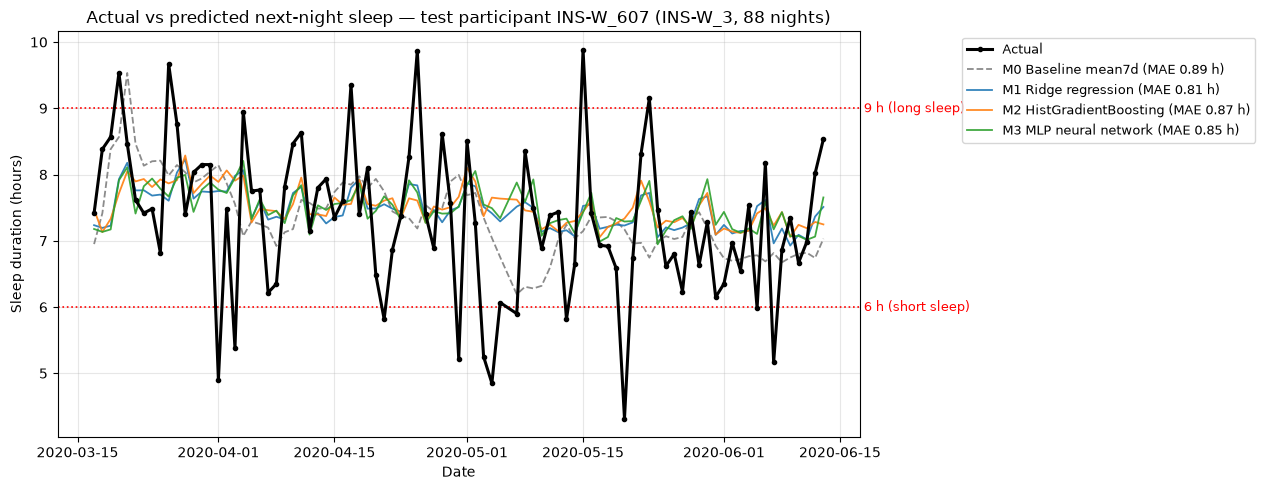

saved: sleep_plot.png


In [39]:
import matplotlib
import matplotlib.pyplot as plt

# เลือกคนใน test ที่มีจำนวนวันมากที่สุด
plot_pid = test["participant_id"].value_counts().idxmax()
pm = (test["participant_id"] == plot_pid).to_numpy()
person = test[pm]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(person["date"], person[TARGET], color="black", lw=2.2, marker="o", ms=3, label="Actual", zorder=5)
styles = {"M0": ("tab:gray", "--"), "M1": ("tab:blue", "-"), "M2": ("tab:orange", "-"), "M3": ("tab:green", "-")}
for key, p in test_pred.items():
    c, ls = styles[key]
    ax.plot(person["date"], p[pm].to_numpy(), color=c, ls=ls, lw=1.3, alpha=0.9,
            label=f"{key} {DESCS[key]} (MAE {mean_absolute_error(person[TARGET], p[pm]):.2f} h)")
for h, lab in [(6, "6 h (short sleep)"), (9, "9 h (long sleep)")]:
    ax.axhline(h, color="red", ls=":", lw=1.2)
    ax.text(1.0, h, " " + lab, color="red", fontsize=9, va="center", transform=ax.get_yaxis_transform())
ax.set_xlabel("Date")
ax.set_ylabel("Sleep duration (hours)")
ax.set_title(f"Actual vs predicted next-night sleep — test participant {plot_pid[:10]} "
             f"({person['cohort'].iloc[0]}, {len(person)} nights)")
ax.legend(loc="upper left", bbox_to_anchor=(1.12, 1), fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("sleep_plot.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved: sleep_plot.png")

### 5.3 ตรวจไฟล์ส่งงาน

In [40]:
for f in ["results.csv", "features_example.csv", "sleep_plot.png", "filter_counts.csv"]:
    print(("OK " if Path(f).exists() else "MISSING ") + f)
chk = pd.read_csv("results.csv")
assert list(chk.columns) == RESULT_COLS and list(chk["MODEL"]) == ["M0", "M1", "M2", "M3"]
assert set(train["participant_id"]).isdisjoint(test["participant_id"])

OK results.csv
OK features_example.csv
OK sleep_plot.png
OK filter_counts.csv


## 6. งานโบนัส — Personalisation

ใช้ **k คืนแรก** ของผู้เข้าร่วม test (k = 0, 3, 7, 14) ที่รู้ค่าจริงแล้ว ประมาณ bias รายบุคคลของโมเดลที่ดีที่สุด

`pred_personal = pred + mean(residual ของ k คืนแรก) × k / (k + λ)`

- λ (shrinkage) เลือกจาก **out-of-fold predictions บน train** (ไม่แตะ test)
- ประเมินบนคืนที่ 15 เป็นต้นไปของแต่ละคน (ชุดแถวเดียวกันทุก k → เทียบกันได้)

In [41]:
KS = [0, 3, 7, 14]
LAMBDAS = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]

def personalised(frame, pred, k, lam):
    """คืนค่า (y, pred_personal) เฉพาะคืนที่ > 14 ของแต่ละคน"""
    f = frame[["participant_id", "date", TARGET]].assign(pred=np.asarray(pred))
    f = f.sort_values(["participant_id", "date"])
    f["night_no"] = f.groupby("participant_id").cumcount()
    f["resid"] = f[TARGET] - f["pred"]
    if k > 0:
        bias = f[f["night_no"] < k].groupby("participant_id")["resid"].mean()
        f["pred"] += f["participant_id"].map(bias).fillna(0) * k / (k + lam)
    ev = f[f["night_no"] >= max(KS)]
    return ev

# เลือก λ บน train (OOF)
lam_scores = {
    lam: np.mean([
        mean_absolute_error(e[TARGET], e["pred"])
        for k in KS[1:] for e in [personalised(train, oof[BEST], k, lam)]
    ])
    for lam in LAMBDAS
}
BEST_LAMBDA = min(lam_scores, key=lam_scores.get)
print("train OOF MAE เฉลี่ย (k=3,7,14) ตาม λ:", {k: round(v, 4) for k, v in lam_scores.items()})
print("λ ที่เลือก =", BEST_LAMBDA)

train OOF MAE เฉลี่ย (k=3,7,14) ตาม λ: {0: np.float64(1.1292), 1: np.float64(1.0948), 2: np.float64(1.0765), 5: np.float64(1.0532), 10: np.float64(1.0415), 20: np.float64(1.0356), 50: np.float64(1.0333), 100: np.float64(1.0332), 200: np.float64(1.0334), 500: np.float64(1.0336), 1000: np.float64(1.0337)}
λ ที่เลือก = 100


,MAE,MAE_GLOBEM,MAE_LIFESNAPS,n_eval
k,,,,
0,1.0928,1.1041,0.9516,6066
3,1.0922,1.1035,0.9513,6066
7,1.0921,1.1034,0.9526,6066
14,1.0914,1.1028,0.9492,6066


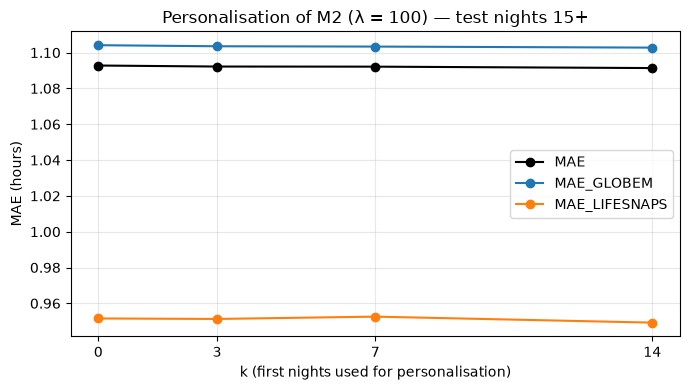

In [42]:
rows = []
for k in KS:
    e = personalised(test, test_pred[BEST], k, BEST_LAMBDA)
    src = test.loc[e.index, "source"]
    rows.append({
        "k": k,
        "MAE": mean_absolute_error(e[TARGET], e["pred"]),
        "MAE_GLOBEM": mean_absolute_error(e.loc[src == "globem", TARGET], e.loc[src == "globem", "pred"]),
        "MAE_LIFESNAPS": mean_absolute_error(e.loc[src == "lifesnaps", TARGET], e.loc[src == "lifesnaps", "pred"]),
        "n_eval": len(e),
    })
personal = pd.DataFrame(rows).set_index("k")
display(personal.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for col, c in [("MAE", "black"), ("MAE_GLOBEM", "tab:blue"), ("MAE_LIFESNAPS", "tab:orange")]:
    ax.plot(personal.index, personal[col], marker="o", color=c, label=col)
ax.set_xticks(KS)
ax.set_xlabel("k (first nights used for personalisation)")
ax.set_ylabel("MAE (hours)")
ax.set_title(f"Personalisation of {BEST} (λ = {BEST_LAMBDA}) — test nights 15+")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("bonus_personalisation.png", dpi=150)
plt.show()

---
สรุปตัวเลขทั้งหมดสำหรับรายงานอยู่ใน `results.csv`, `filter_counts.csv` และตารางในส่วนที่ 3–6